# A2 · Features and leakage check

Real Kaggle members only. Features come from `anchorai.features.build_features`; this notebook
inspects them and runs the leakage check: the churn model is trained
with and without the columns that may be measured in the same month as the churn label.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anchorai.config import get_settings
from anchorai.features import build_features
from anchorai.scenario.tables import read_tables

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = get_settings().anchorai_seed
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

tables = read_tables()
members = tables["members"]
labels = members.set_index("member_id")
features = build_features(members)
is_train = labels["split"] == "train"
print(len(members), "members;", is_train.sum(), "train /", (~is_train).sum(), "test")

4000 members; 3200 train / 800 test


In [2]:
from anchorai.features import FEATURES, LABELS, SUSPECT

features.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
gender,4000.0,0.51,0.50,0.00,0.00,1.00,1.00,1.00
near_location,4000.0,0.85,0.36,0.00,1.00,1.00,1.00,1.00
partner,4000.0,0.49,0.50,0.00,0.00,0.00,1.00,1.00
promo_friends,4000.0,0.31,0.46,0.00,0.00,0.00,1.00,1.00
phone,4000.0,0.90,0.30,0.00,1.00,1.00,1.00,1.00
group_visits,4000.0,0.41,0.49,0.00,0.00,0.00,1.00,1.00
contract_period,4000.0,4.68,4.55,1.00,1.00,1.00,6.00,12.00
age,4000.0,29.18,3.26,18.00,27.00,29.00,31.00,41.00
avg_additional_charges_total,4000.0,146.94,96.36,0.15,68.87,136.22,210.95,552.59
lifetime,4000.0,3.72,3.75,0.00,1.00,3.00,5.00,31.00


## Trend signal (the deck's "12 → 4 visits")
`trend_ratio` = visits per week this month ÷ lifetime visits per week.

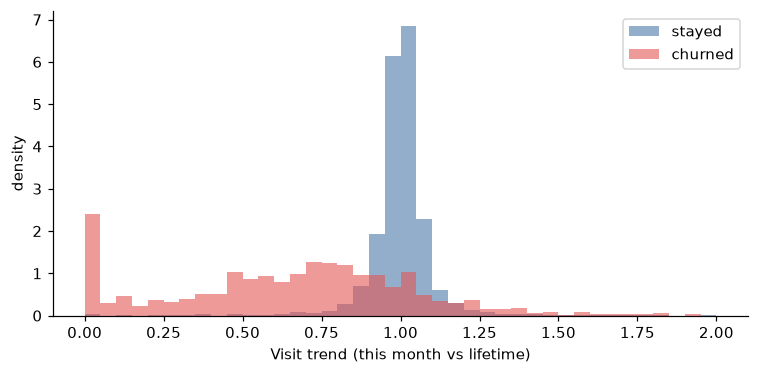

,trend_ratio,lifetime,month_to_end_contract
churn,,,
0,1.000380,4.0,6.0
1,0.696348,1.0,1.0


In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for churn, colour in ((0, "#4c78a8"), (1, "#e45756")):
    ax.hist(features.loc[labels["churn"] == churn, "trend_ratio"], bins=40, range=(0, 2),
            alpha=0.6, color=colour, label="churned" if churn else "stayed", density=True)
ax.set_xlabel(LABELS["trend_ratio"]); ax.set_ylabel("density"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "a2_trend_ratio.png"); plt.show()
features.assign(churn=labels["churn"]).groupby("churn")[["trend_ratio", "lifetime", "month_to_end_contract"]].median()

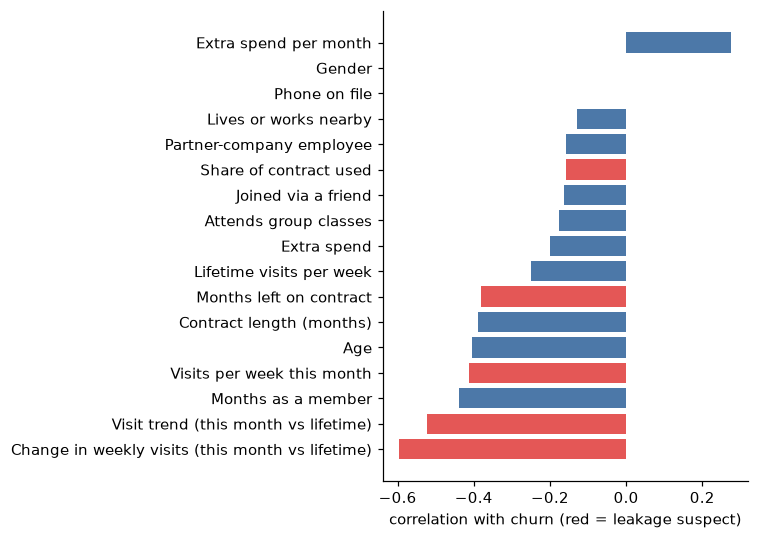

In [4]:
corr = features.assign(churn=labels["churn"]).corr()["churn"].drop("churn").sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
colours = ["#e45756" if c in SUSPECT else "#4c78a8" for c in corr.index]
ax.barh([LABELS[c] for c in corr.index], corr.values, color=colours)
ax.set_xlabel("correlation with churn (red = leakage suspect)")
fig.tight_layout(); fig.savefig(FIG / "a2_feature_correlation.png"); plt.show()

## Leakage check
Same model family, resampling and calibration; only the column set changes. Metrics on the untouched test split.

In [5]:
from anchorai.discovery import churn

result = churn.train(features, labels["churn"], labels["split"], SEED)
leak = result.card["leakage"]
rows = {
    variant: {"features": len(v["columns"]), **{f"cv_{k}": v["cv"][k] for k in ("f1", "pr_auc", "brier")},
              **{f"test_{k}": v["test"][k] for k in ("f1", "pr_auc", "brier")}}
    for variant, v in leak.items()
}
leakage = pd.DataFrame(rows).T.round(3)
leakage

,features,cv_f1,cv_pr_auc,cv_brier,test_f1,test_pr_auc,test_brier
with_suspect,17.0,0.906,0.972,0.039,0.908,0.973,0.035
without_suspect,12.0,0.814,0.897,0.078,0.817,0.900,0.069


In [6]:
def markdown(frame):
    head = "| variant | " + " | ".join(frame.columns) + " |"
    rule = "|" + "---|" * (len(frame.columns) + 1)
    body = ["| " + " | ".join([str(i), *map(str, r)]) + " |" for i, r in zip(frame.index, frame.values.tolist())]
    return "\n".join([head, rule, *body])

gap = leakage.loc["with_suspect", "test_pr_auc"] - leakage.loc["without_suspect", "test_pr_auc"]
note = f"""# Leakage check (A2)

Suspect columns: {", ".join(SUSPECT)}.

{markdown(leakage)}

Dropping the suspect set lowers test PR-AUC by {gap:.3f}. The signal is real but not the whole
model: without the suspect set the ensemble still reaches PR-AUC {leakage.loc["without_suspect", "test_pr_auc"]:.3f}.
The production model keeps the suspect columns because the current month's visits and the months
left on the contract are both known at the time the weekly plan is made. If the Kaggle label was
recorded after that month ended, the "without" row is the honest estimate; the report shows both.
"""
(RES / "a_leakage.md").write_text(note)
leakage.to_csv(RES / "a_leakage.csv")
print(note)

# Leakage check (A2)

Suspect columns: month_to_end_contract, contract_progress, avg_class_frequency_current_month, trend_ratio, visit_change.

| variant | features | cv_f1 | cv_pr_auc | cv_brier | test_f1 | test_pr_auc | test_brier |
|---|---|---|---|---|---|---|---|
| with_suspect | 17.0 | 0.906 | 0.972 | 0.039 | 0.908 | 0.973 | 0.035 |
| without_suspect | 12.0 | 0.814 | 0.897 | 0.078 | 0.817 | 0.9 | 0.069 |

Dropping the suspect set lowers test PR-AUC by 0.073. The signal is real but not the whole
model: without the suspect set the ensemble still reaches PR-AUC 0.900.
The production model keeps the suspect columns because the current month's visits and the months
left on the contract are both known at the time the weekly plan is made. If the Kaggle label was
recorded after that month ended, the "without" row is the honest estimate; the report shows both.

